# Explore here

Datos completos: (20640, 9)
Train: (16512, 9)
Test:  (4128, 9)
Tipo de cluster: category
Clusters presentes: [0, 1, 2, 3, 4, 5]
Casas por cluster en todo el conjunto:
cluster
0    4757
1    8015
2    3916
3       1
4    3873
5      78
Name: count, dtype: int64
Predicciones en test por cluster:
cluster
0     898
1    1626
2     801
3       0
4     789
5      14
Name: count, dtype: int64


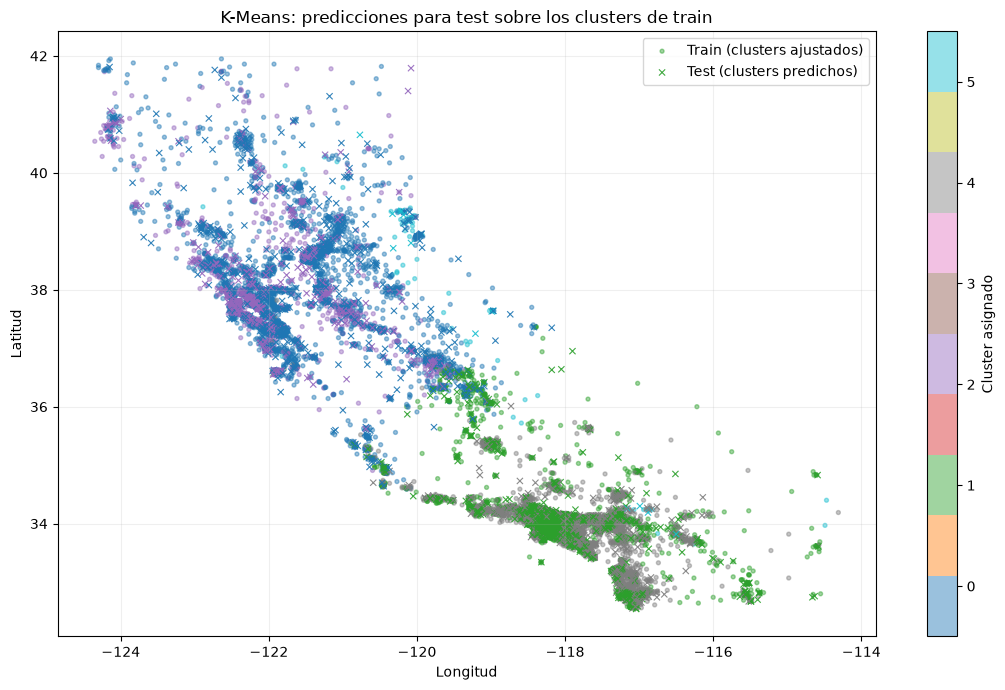

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Cargar los datos originales (funciona tanto desde la raíz del proyecto como desde src/).
data_path = Path("data/raw/housing.csv")
if not data_path.exists():
    data_path = Path("../data/raw/housing.csv")

housing = pd.read_csv(data_path)

# Reservar el 20 % para pruebas; la semilla hace que la división sea reproducible.
train, test = train_test_split(
    housing,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print(f"Datos completos: {housing.shape}")
print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")

# MedHouseVal es el valor objetivo, no una característica de entrada del clustering.
features = housing.columns.drop("MedHouseVal")

# Estandarizar es importante: K-Means utiliza distancias y las variables tienen escalas distintas.
scaler = StandardScaler()
X_train = scaler.fit_transform(train[features])
X_test = scaler.transform(test[features])

# Ajustar únicamente con train; test solo recibe predicciones del modelo ya entrenado.
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
train["cluster"] = kmeans.fit_predict(X_train)
test["cluster"] = kmeans.predict(X_test)

# Etiquetar también el conjunto completo con el mismo modelo entrenado en train.
housing["cluster"] = kmeans.predict(scaler.transform(housing[features]))
cluster_categories = list(range(kmeans.n_clusters))
for dataset in (train, test, housing):
    dataset["cluster"] = pd.Categorical(
        dataset["cluster"], categories=cluster_categories
    )

print("Tipo de cluster:", housing["cluster"].dtype)
print("Clusters presentes:", sorted(housing["cluster"].cat.categories.tolist()))
print("Casas por cluster en todo el conjunto:")
print(housing["cluster"].value_counts().sort_index())
print("Predicciones en test por cluster:")
print(test["cluster"].value_counts().sort_index())

# Diagrama geográfico: círculos = train; cruces = test predicho por el modelo.
fig, ax = plt.subplots(figsize=(11, 7))
train_scatter = ax.scatter(
    train["Longitude"],
    train["Latitude"],
    c=train["cluster"].cat.codes,
    cmap="tab10",
    vmin=-0.5,
    vmax=5.5,
    s=8,
    alpha=0.45,
    label="Train (clusters ajustados)",
)
ax.scatter(
    test["Longitude"],
    test["Latitude"],
    c=test["cluster"].cat.codes,
    cmap="tab10",
    vmin=-0.5,
    vmax=5.5,
    marker="x",
    s=20,
    linewidths=0.8,
    alpha=0.9,
    label="Test (clusters predichos)",
)
colorbar = fig.colorbar(train_scatter, ax=ax, ticks=range(6))
colorbar.set_label("Cluster asignado")
ax.set(
    title="K-Means: predicciones para test sobre los clusters de train",
    xlabel="Longitud",
    ylabel="Latitud",
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

### Interpretación del gráfico

Los círculos representan los datos de entrenamiento con los que se ajustaron los centroides; las cruces son las casas de `test`, a las que se asignó el cluster del centroide más cercano. Como los puntos de test se intercalan en las mismas regiones y tienen los mismos colores que los puntos de entrenamiento cercanos, la asignación parece coherente con la estructura geográfica observada. Esto permite inspeccionar que el modelo asigna clusters a datos no vistos durante el ajuste, pero no mide exactitud: en clustering no hay etiquetas verdaderas con las que comparar, y los números de cluster son identificadores arbitrarios. Los tamaños desiguales de los grupos también son normales en K-Means.

Accuracy frente a etiquetas K-Means: 0.9763
Balanced accuracy: 0.9797

Informe de clasificación (referencia: predicciones de K-Means en test):
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       898
           1       0.98      0.98      0.98      1626
           2       0.98      0.98      0.98       801
           3       0.00      0.00      0.00         0
           4       0.97      0.96      0.96       789
           5       0.93      1.00      0.97        14

    accuracy                           0.98      4128
   macro avg       0.81      0.82      0.81      4128
weighted avg       0.98      0.98      0.98      4128



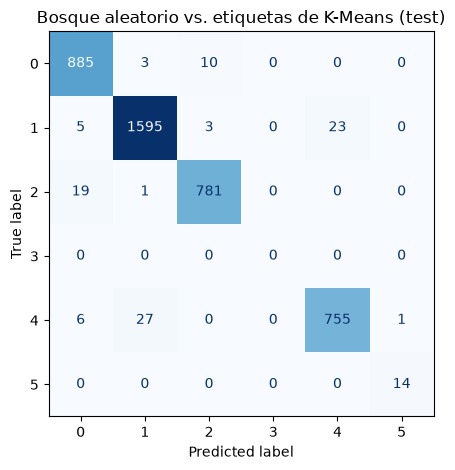

Características más importantes para reproducir los clusters:
HouseAge      0.207
Latitude      0.151
AveRooms      0.145
Longitude     0.137
AveBedrms     0.112
Population    0.093
MedInc        0.084
AveOccup      0.071
dtype: float64


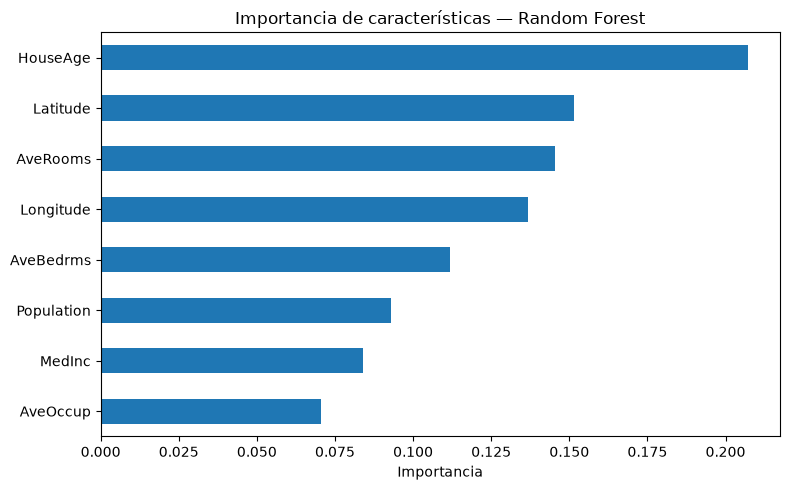

Modelos guardados en: /workspaces/machine-learning-python-template-owner-Miguel-Contreras/models


In [2]:
from pathlib import Path

import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Los clusters de K-Means actúan como etiquetas generadas automáticamente.
# El bosque aleatorio aprende a reproducir esa asignación a partir de las características.
cluster_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
cluster_model.fit(train[features], train["cluster"].astype(int))

# Evaluar en test contra las etiquetas de cluster que K-Means predijo para esos datos.
test_cluster_prediction = cluster_model.predict(test[features])
test_cluster_labels = test["cluster"].astype(int)
labels = list(range(kmeans.n_clusters))

print("Accuracy frente a etiquetas K-Means:", round(accuracy_score(test_cluster_labels, test_cluster_prediction), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(test_cluster_labels, test_cluster_prediction), 4))
print("\nInforme de clasificación (referencia: predicciones de K-Means en test):")
print(classification_report(
    test_cluster_labels,
    test_cluster_prediction,
    labels=labels,
    zero_division=0,
))

confusion = confusion_matrix(test_cluster_labels, test_cluster_prediction, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=labels).plot(
    cmap="Blues", values_format="d", colorbar=False
)
plt.title("Bosque aleatorio vs. etiquetas de K-Means (test)")
plt.tight_layout()
plt.show()

importance = pd.Series(cluster_model.feature_importances_, index=features).sort_values()
print("Características más importantes para reproducir los clusters:")
print(importance.tail(10).sort_values(ascending=False).round(3))
importance.sort_values().plot(kind="barh", figsize=(8, 5), title="Importancia de características — Random Forest")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

# Guardar los modelos en models/. El artefacto de K-Means incluye el scaler
# y el orden de las variables, necesarios para predecir sobre datos nuevos.
models_dir = Path("models")
if not models_dir.is_dir() and Path("../models").is_dir():
    models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {"model": kmeans, "scaler": scaler, "features": list(features)},
    models_dir / "kmeans_housing.joblib",
)
joblib.dump(cluster_model, models_dir / "random_forest_cluster.joblib")
print(f"Modelos guardados en: {models_dir.resolve()}")

### Selección e interpretación del modelo supervisado

Se utiliza un `RandomForestClassifier`: captura relaciones no lineales e interacciones entre variables sin exigir escalado adicional, y permite inspeccionar la importancia de las características. Aprende a reproducir las etiquetas de cluster generadas por K-Means; por tanto, sus métricas miden concordancia con ese modelo, no si los grupos son «verdaderos» ni si predicen el precio de la vivienda. Se evalúa en `test`, que no intervino en el ajuste del bosque. La matriz de confusión y el informe ayudan a identificar aciertos y clases difíciles; la *balanced accuracy* resulta útil porque los clusters están muy desbalanceados. Revisa también qué variables tienen mayor importancia: deberían reflejar las reglas de agrupación aprendidas por K-Means.

### Resultados observados

En esta partición, el bosque aleatorio alcanza **97,63 % de accuracy** y **97,97 % de balanced accuracy** al reproducir las asignaciones de K-Means en `test`. Las clases 0, 1, 2 y 4 tienen F1 cercano a 0,96–0,98; la clase 5 obtiene F1 de 0,97, aunque solo tiene 14 ejemplos en test. La clase 3 no aparece en test (soporte 0; su único punto del conjunto completo quedó en train), por lo que no se puede evaluar su generalización y su fila del informe no es interpretable. Las variables más influyentes fueron `HouseAge`, `Latitude`, `AveRooms` y `Longitude`. En conjunto el clasificador replica bien las asignaciones frecuentes, pero la cifra alta mide fidelidad al etiquetado de K-Means, no una exactitud objetiva de segmentación ni una predicción del precio. Conviene ser cautelosos con las clases raras: hay muy pocos ejemplos para estimar su rendimiento con confianza.